# License Plate Recognition with a Custom CNN and CTC

This notebook trains a recognition model from scratch to read cropped Iranian license plates. Each cleaned label contains two digits, one letter, and five more digits. Plate detection is handled separately; the input here is already a plate crop.

The workflow covers data preparation, character encoding, the CNN architecture, training, validation, inference timing, and visual inspection of mistakes. The model combines Inception-style branches with efficient convolution blocks and reads the resulting feature sequence using CTC.

Run the cells in order in Google Colab. The training section starts a new run; it does not automatically resume a checkpoint. Files under `/content` are temporary, so choose a folder in mounted Google Drive for `save_folder` if you want to retain checkpoints and reports. Evaluation in this notebook uses the validation split; a separate test set is needed for final performance reporting.

## 1. Imports and dataset download

All Python imports are collected below. PyTorch handles the model and training, torchvision prepares images, pandas manages labels, and Matplotlib displays images and results. The remaining libraries support file handling, timing, and progress bars.

The download cells use the `gdown` command to fetch the LPR archive, then extract it into `/content/LPR_FILES`. Skip downloading and extraction if the dataset is already available there. The notebook expects a `detections` image folder and a `valid_samples.csv` label file.

In [1]:
import math
import os
import platform
import random
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm


In [2]:
!gdown --fuzzy https://drive.google.com/file/d/1Me3Bk1mmITaf5QQE5Kvk1E1d8xaqsnhf/view?usp=drive_link

!mkdir /content/LPR_FILES
!unzip LPR.zip -d /content/LPR_FILES


Streaming output truncated to the last 5000 lines.
  inflating: /content/LPR_FILES/detections/5499.jpg  
  inflating: /content/LPR_FILES/detections/55.jpg  
  inflating: /content/LPR_FILES/detections/550.jpg  
  inflating: /content/LPR_FILES/detections/5500.jpg  
  inflating: /content/LPR_FILES/detections/5501.jpg  
  inflating: /content/LPR_FILES/detections/5502.jpg  
  inflating: /content/LPR_FILES/detections/5503.jpg  
  inflating: /content/LPR_FILES/detections/5504.jpg  
  inflating: /content/LPR_FILES/detections/5505.jpg  
  inflating: /content/LPR_FILES/detections/5506.jpg  
  inflating: /content/LPR_FILES/detections/5507.jpg  
  inflating: /content/LPR_FILES/detections/5508.jpg  
  inflating: /content/LPR_FILES/detections/5509.jpg  
  inflating: /content/LPR_FILES/detections/551.jpg  
  inflating: /content/LPR_FILES/detections/5510.jpg  
  inflating: /content/LPR_FILES/detections/5511.jpg  
  inflating: /content/LPR_FILES/detections/5512.jpg  
  inflating: /content/LPR_FILES/det

## 2. Read and clean the labels

The CSV connects each filename to its plate text. Labels are read as strings so leading zeros are retained, and `original_label` preserves the unmodified text for reference.

For this dataset, `الف` and `آ` are mapped to `ا`, following the visual inspection of those classes. Invisible joining characters are removed. The cleaned pattern must contain exactly two digits, one letter, and five digits. We also check that every image exists and that image filenames are unique.

Cleaning happens before the split so alternate spellings of the same plate cannot place that identity in both sets. Failed checks stop the notebook for inspection rather than silently removing samples.

In [3]:
data_folder = "/content/LPR_FILES"

all_files = []

for folder, subfolders, filenames in os.walk(data_folder):
    for filename in filenames:
        file_path = os.path.join(folder, filename)
        all_files.append(file_path)

all_files.sort()

print("Total files:", len(all_files))

file_types = Counter()

for file_path in all_files:
    extension = os.path.splitext(file_path)[1].lower()
    file_types[extension] += 1

print("\nFile types:")
print(file_types)

print("\nFirst 20 file paths:")

for file_path in all_files[:20]:
    print(os.path.relpath(file_path, data_folder))

csv_path = "/content/LPR_FILES/valid_samples.csv"
labels = pd.read_csv(csv_path, dtype=str)
labels["original_label"] = labels["label"]

print("Number of rows:", len(labels))
display(labels.head(10))
print("Missing values:")
print(labels.isna().sum())

assert labels[["image_path", "label"]].notna().all().all(), "Check missing filenames or labels."


Total files: 24562

File types:
Counter({'.jpg': 24561, '.csv': 1})

First 20 file paths:
detections/1.jpg
detections/10.jpg
detections/100.jpg
detections/1000.jpg
detections/10000.jpg
detections/10001.jpg
detections/10002.jpg
detections/10003.jpg
detections/10004.jpg
detections/10005.jpg
detections/10006.jpg
detections/10007.jpg
detections/10008.jpg
detections/10009.jpg
detections/1001.jpg
detections/10010.jpg
detections/10011.jpg
detections/10012.jpg
detections/10013.jpg
detections/10014.jpg
Number of rows: 24561


,image_path,label,original_label
0,1.jpg,98ع89511,98ع89511
1,2.jpg,19ش24611,19ش24611
2,3.jpg,25ت71433,25ت71433
3,4.jpg,95ت38633,95ت38633
4,5.jpg,44ه67355,44ه67355
5,6.jpg,68ث81811,68ث81811
6,7.jpg,93ث76811,93ث76811
7,8.jpg,74ج82499,74ج82499
8,9.jpg,67ژ18611,67ژ18611
9,10.jpg,99س85855,99س85855


Missing values:
image_path        0
label             0
original_label    0
dtype: int64


In [4]:
labels["image_path"] = labels["image_path"].str.strip()
labels["label"] = labels["original_label"].str.strip()

labels["label"] = labels["label"].str.replace("الف", "ا", regex=False)
labels["label"] = labels["label"].str.replace("آ", "ا", regex=False)

labels["label"] = labels["label"].str.replace("\u200d", "", regex=False)
labels["label"] = labels["label"].str.replace("\u200c", "", regex=False)

valid_format = labels["label"].str.fullmatch(
    r"[0-9]{2}[^\W\d_][0-9]{5}",
    na=False
)

print("Valid labels:", valid_format.sum())
print("Unexpected labels:", (~valid_format).sum())

if not valid_format.all():
    display(
        labels.loc[~valid_format, ["image_path", "original_label"]].head(20)
    )

assert valid_format.all(), "Some labels still need inspection."

print("\nLetter classes and sample counts:")
print(labels["label"].str[2].value_counts())

image_folder = "/content/LPR_FILES/detections"
missing_images = []

for filename in labels["image_path"]:
    image_path = os.path.join(image_folder, filename)
    if not os.path.isfile(image_path):
        missing_images.append(filename)

print("Total samples:", len(labels))
print("Unique plates:", labels["label"].nunique())
print("Missing images:", len(missing_images))

if missing_images:
    print(missing_images[:10])

assert len(missing_images) == 0, "Some images are missing."
assert labels["image_path"].is_unique, "Repeated image filenames need inspection."


Valid labels: 24561
Unexpected labels: 0

Letter classes and sample counts:
label
د    2267
ص    2255
ق    2018
م    1903
ج    1901
ب    1862
و    1828
س    1749
ط    1724
ل    1518
ن    1480
ه    1421
ی    1332
ت     709
ع     491
ا      66
ژ      30
ث       3
ش       2
ز       1
پ       1
Name: count, dtype: int64
Total samples: 24561
Unique plates: 20905
Missing images: 0


## 3. Split the data and preview plate images

The split uses **90% of unique plate identities for training and 10% for validation**. All images with the same cleaned plate text remain together, so the image-count percentages may differ slightly from 90/10. A fixed seed makes the identity split reproducible; it does not make the entire training run deterministic.

The cells display letter counts in both sets, save the split CSV files, and show six training images. Check these examples for image quality and label consistency. Labels are printed as lists of symbols to make their stored order clear when Persian text is displayed.

In [5]:
unique_plates = sorted(labels["label"].unique())
assert len(unique_plates) >= 2, "At least two unique plates are needed."

random_generator = random.Random(42)
random_generator.shuffle(unique_plates)
split_index = int(len(unique_plates) * 0.9)

train_plates = unique_plates[:split_index]
val_plates = unique_plates[split_index:]

train_df = labels[labels["label"].isin(train_plates)].copy()
val_df = labels[labels["label"].isin(val_plates)].copy()
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

assert set(train_df["label"]).isdisjoint(set(val_df["label"]))
assert len(train_df) + len(val_df) == len(labels)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print(f"Training percentage: {100 * len(train_df) / len(labels):.1f}%")
print(f"Validation percentage: {100 * len(val_df) / len(labels):.1f}%")

letter_counts = pd.DataFrame({
    "train": train_df["label"].str[2].value_counts(),
    "validation": val_df["label"].str[2].value_counts()
})
letter_counts = letter_counts.fillna(0).astype(int).sort_index()
display(letter_counts)

if (letter_counts == 0).any().any():
    print("Some letters are missing from one split. Review before training.")

train_df.to_csv("/content/LPR_FILES/train.csv", index=False)
val_df.to_csv("/content/LPR_FILES/val.csv", index=False)
print("Saved train.csv and val.csv. Copy them to Drive to keep the split.")


Training samples: 22161
Validation samples: 2400
Training percentage: 90.2%
Validation percentage: 9.8%


,train,validation
label,,
ا,60,6
ب,1664,198
ت,636,73
ث,3,0
ج,1719,182
د,2066,201
ز,1,0
س,1553,196
ش,2,0


Some letters are missing from one split. Review before training.
Saved train.csv and val.csv. Copy them to Drive to keep the split.


16288.jpg — label symbols: ['5', '1', 'ج', '4', '9', '9', '9', '9']
6983.jpg — label symbols: ['3', '1', 'د', '7', '1', '6', '1', '6']
13204.jpg — label symbols: ['6', '3', 'ط', '3', '7', '6', '9', '9']
9459.jpg — label symbols: ['4', '7', 'ه', '8', '4', '3', '1', '0']
9101.jpg — label symbols: ['7', '7', 'ی', '1', '6', '1', '1', '1']
3631.jpg — label symbols: ['6', '8', 'و', '3', '6', '8', '2', '2']


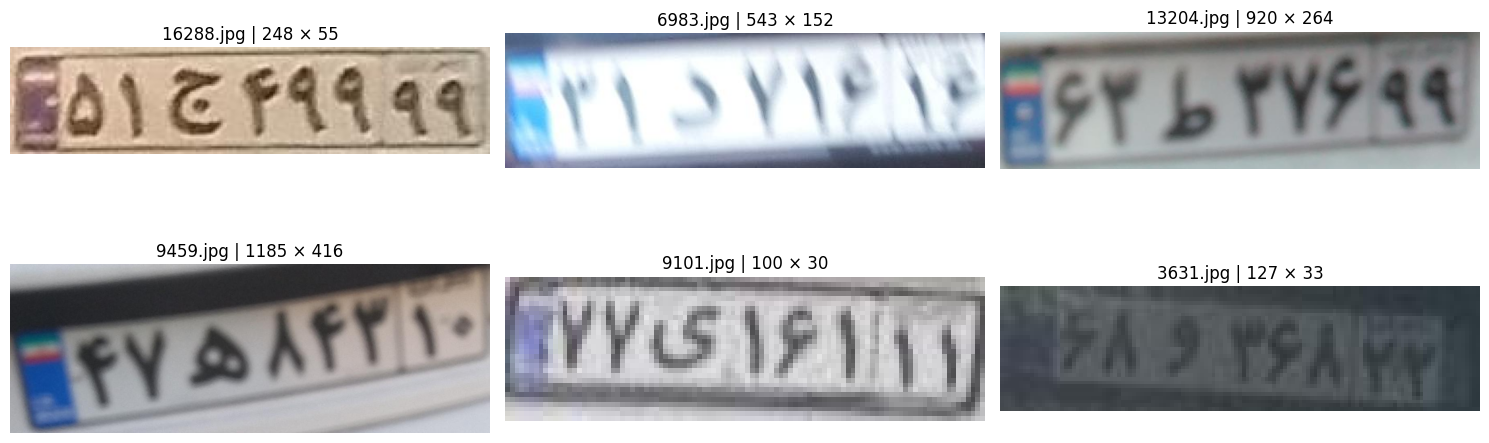

In [6]:
samples = train_df.sample(n=min(6, len(train_df)), random_state=42)

plt.figure(figsize=(15, 6))

for position, (_, row) in enumerate(samples.iterrows()):
    image_path = os.path.join(image_folder, row["image_path"])

    with Image.open(image_path) as file:
        image = file.convert("RGB")

    plt.subplot(2, 3, position + 1)
    plt.imshow(image)
    plt.title(f"{row['image_path']} | {image.width} × {image.height}")
    plt.axis("off")

    print(row["image_path"], "— label symbols:", list(row["label"]))

plt.tight_layout()
plt.show()


## 4. Build the CTC character vocabulary

Digits and letters share one vocabulary. Class `0` is reserved for the CTC blank, digit characters receive IDs starting at `1`, and letter IDs follow. The digit `"0"` is therefore different from the blank class.

The vocabulary is built from training data, then checked against validation labels. The two mappings convert text to class IDs and predictions back to text. A short encoding example confirms that a label can be reconstructed exactly. Correct target labels contain no blanks; CTC learns where blanks belong in the output sequence.

In [7]:
letters = sorted(train_df["label"].str[2].unique())

digits = list("0123456789")
characters = digits + letters

blank_id = 0

character_to_index = {}
index_to_character = {}

for index, character in enumerate(characters, start=1):
    character_to_index[character] = index
    index_to_character[index] = character

num_classes = len(characters) + 1

print("Number of classes, including blank:", num_classes)
print("Character mapping:", character_to_index)

unknown_characters = set()

for label in val_df["label"]:
    for character in label:
        if character not in character_to_index:
            unknown_characters.add(character)

assert not unknown_characters, (
    f"Characters missing from training: {unknown_characters}"
)

print("All validation characters are supported.")


Number of classes, including blank: 32
Character mapping: {'0': 1, '1': 2, '2': 3, '3': 4, '4': 5, '5': 6, '6': 7, '7': 8, '8': 9, '9': 10, 'ا': 11, 'ب': 12, 'ت': 13, 'ث': 14, 'ج': 15, 'د': 16, 'ز': 17, 'س': 18, 'ش': 19, 'ص': 20, 'ط': 21, 'ع': 22, 'ق': 23, 'ل': 24, 'م': 25, 'ن': 26, 'ه': 27, 'و': 28, 'پ': 29, 'ژ': 30, 'ی': 31}
All validation characters are supported.


In [8]:
example_label = train_df.iloc[0]["label"]

encoded_label = []

for character in example_label:
    encoded_label.append(character_to_index[character])

decoded_label = ""

for index in encoded_label:
    decoded_label += index_to_character[index]

print("Original symbols:", list(example_label))
print("Encoded label:", encoded_label)
print("Decoded symbols:", list(decoded_label))

assert decoded_label == example_label
assert blank_id not in encoded_label


Original symbols: ['9', '8', 'ع', '8', '9', '5', '1', '1']
Encoded label: [10, 9, 22, 9, 10, 6, 2, 2]
Decoded symbols: ['9', '8', 'ع', '8', '9', '5', '1', '1']


## 5. Prepare images and batches

Every image is converted to RGB, resized to **64 × 256** pixels, and normalized from pixel values in `[0, 1]` to approximately `[-1, 1]`. Resizing fixes the input shape but can change the original aspect ratio; the preview helps check that characters remain readable.

With `use_augmentation=True`, training also uses small rotations, shifts, scale changes, and brightness/contrast adjustments. These introduce mild variation without reversing the text. Validation always uses deterministic resizing and normalization. Set the flag to `False` for an experiment without augmentation.

`PlateDataset` loads images on demand and returns the image, encoded label, and label length. All cleaned labels contain eight symbols, so the default DataLoader can stack them directly. Training batches are shuffled; validation batches preserve order. `num_workers=0` avoids the worker-cleanup errors encountered in Colab.

| Batch item | Shape | Purpose |
| --- | --- | --- |
| Images | `[batch, 3, 64, 256]` | Input to the CNN |
| Targets | `[batch, 8]` | Correct character IDs |
| Target lengths | `[batch]` | Number of characters in each label |

The preview and sample cells inspect the data format. They do not train the model.

Original size (width, height): (109, 45)
Tensor shape: torch.Size([3, 64, 256])
Minimum value: -0.9843137264251709
Maximum value: 1.0


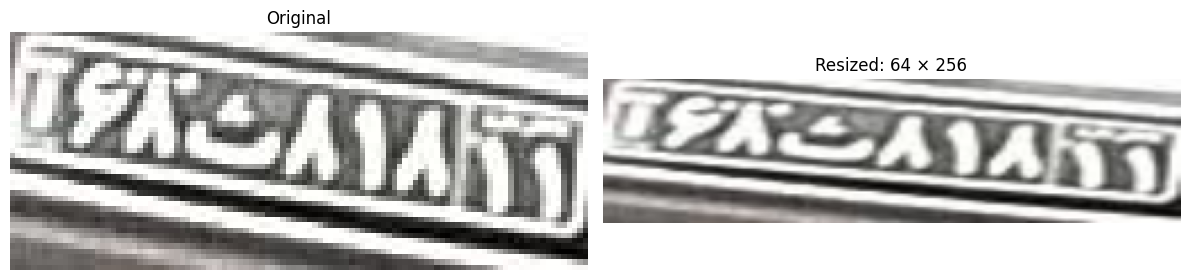

In [9]:
use_augmentation = True

image_transform = transforms.Compose([
    transforms.Resize((64, 256)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

if use_augmentation:
    train_transform = transforms.Compose([
        transforms.Resize((64, 256)),
        transforms.RandomApply([
            transforms.RandomAffine(
                degrees=2,
                translate=(0.01, 0.02),
                scale=(0.98, 1.02),
                interpolation=transforms.InterpolationMode.BILINEAR,
                fill=128
            )
        ], p=0.5),
        transforms.ColorJitter(brightness=0.15, contrast=0.15),
        transforms.ToTensor(),
        transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
    ])
else:
    train_transform = image_transform

image_path = os.path.join(
    image_folder,
    train_df.iloc[4]["image_path"]
)

with Image.open(image_path) as file:
    image = file.convert("RGB")

image_tensor = image_transform(image)

print("Original size (width, height):", image.size)
print("Tensor shape:", image_tensor.shape)
print("Minimum value:", image_tensor.min().item())
print("Maximum value:", image_tensor.max().item())

preview = image_tensor * 0.5 + 0.5
preview = preview.permute(1, 2, 0)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(preview)
plt.title("Resized: 64 × 256")
plt.axis("off")

plt.tight_layout()
plt.show()


In [10]:
class PlateDataset(Dataset):
    def __init__(self, dataframe, image_folder, transform, character_to_index):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_folder = image_folder
        self.transform = transform
        self.character_to_index = character_to_index

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = os.path.join(self.image_folder, row["image_path"])

        with Image.open(image_path) as file:
            image = file.convert("RGB")

        image = self.transform(image)

        label = row["label"]
        target = []

        for character in label:
            target.append(self.character_to_index[character])

        target = torch.tensor(target, dtype=torch.long)
        target_length = len(target)

        return image, target, target_length


In [11]:
train_dataset = PlateDataset(
    dataframe=train_df,
    image_folder=image_folder,
    transform=train_transform,
    character_to_index=character_to_index
)

val_dataset = PlateDataset(
    dataframe=val_df,
    image_folder=image_folder,
    transform=image_transform,
    character_to_index=character_to_index
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

image, target, target_length = train_dataset[0]

print("Image shape:", image.shape)
print("Target shape:", target.shape)
print("Original symbols:", list(train_df.iloc[0]["label"]))
print("Numeric target:", target.tolist())
print("Target length:", target_length)


Training samples: 22161
Validation samples: 2400
Image shape: torch.Size([3, 64, 256])
Target shape: torch.Size([8])
Original symbols: ['9', '8', 'ع', '8', '9', '5', '1', '1']
Numeric target: [10, 9, 22, 9, 10, 6, 2, 2]
Target length: 8


In [12]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

images, targets, target_lengths = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Target batch shape:", targets.shape)
print("Target lengths:", target_lengths.tolist())
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Image batch shape: torch.Size([32, 3, 64, 256])
Target batch shape: torch.Size([32, 8])
Target lengths: [8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8]
Training batches: 693
Validation batches: 75


## 6. Build the feature-extraction blocks

The feature extractor uses four reusable components. Their names and parameter structure are preserved so existing checkpoints for this architecture remain compatible.

- **ConvBlock** applies a convolution, BatchNorm, and SiLU. Convolutions learn patterns, normalization controls feature scale, and the activation introduces nonlinearity.
- **InceptionResidualBlock** processes the same input through three branches: a `1 × 1` convolution, a reduced `3 × 3` path, and a reduced path with two `3 × 3` convolutions. Their outputs are concatenated and fused back to the input channel count before residual addition.
- **ChannelAttention** averages each channel spatially, predicts a channel weight, and rescales the features. This is a squeeze-and-excitation mechanism.
- **EfficientBlock** expands channels by a factor of two, applies depthwise spatial filtering and channel attention, then projects to the output width. A skip connection is used only when the shapes match. The final projection has no activation.

These are adaptations of established ideas, not exact reproductions of Inception or EfficientNet. All model weights start from PyTorch's default initialization; no pretrained weights are loaded.

In [13]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, groups=1):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=kernel_size,
                stride=stride,
                padding=kernel_size // 2,
                groups=groups,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.SiLU()
        )

    def forward(self, x):
        return self.layers(x)

class InceptionResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()

        branch_channels = channels // 2

        self.branch1 = ConvBlock(channels, branch_channels, kernel_size=1)

        self.branch2 = nn.Sequential(
            ConvBlock(channels, branch_channels, kernel_size=1),
            ConvBlock(branch_channels, branch_channels)
        )

        self.branch3 = nn.Sequential(
            ConvBlock(channels, branch_channels, kernel_size=1),
            ConvBlock(branch_channels, branch_channels),
            ConvBlock(branch_channels, branch_channels)
        )

        self.fusion = nn.Sequential(
            nn.Conv2d(branch_channels * 3, channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(channels)
        )
        self.activation = nn.SiLU()

    def forward(self, x):
        branch1 = self.branch1(x)
        branch2 = self.branch2(x)
        branch3 = self.branch3(x)

        features = torch.cat([branch1, branch2, branch3], dim=1)
        features = self.fusion(features)

        return self.activation(x + features)


In [14]:
class ChannelAttention(nn.Module):
    def __init__(self, channels):
        super().__init__()

        hidden_channels = max(channels // 8, 1)

        self.layers = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(channels, hidden_channels, kernel_size=1),
            nn.SiLU(),
            nn.Conv2d(hidden_channels, channels, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        weights = self.layers(x)
        return x * weights

class EfficientBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=(1, 1)):
        super().__init__()

        expanded_channels = in_channels * 2
        self.use_residual = in_channels == out_channels and stride == (1, 1)

        self.expand = ConvBlock(in_channels, expanded_channels, kernel_size=1)

        self.depthwise = ConvBlock(
            expanded_channels,
            expanded_channels,
            kernel_size=3,
            stride=stride,
            groups=expanded_channels
        )

        self.attention = ChannelAttention(expanded_channels)

        self.project = nn.Sequential(
            nn.Conv2d(expanded_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels)
        )

    def forward(self, x):
        features = self.expand(x)
        features = self.depthwise(features)
        features = self.attention(features)
        features = self.project(features)

        if self.use_residual:
            features = x + features

        return features


## 7. Assemble the sequence recognizer

The CNN reduces image height more aggressively than width, preserving horizontal detail for the plate's character sequence. Averaging over height produces 64 ordered feature vectors. LayerNorm normalizes each vector, two 1D convolutions exchange information between neighboring positions, and dropout regularizes the sequence features.

The classifier predicts a score for every vocabulary entry, including blank, at each position. It returns float32 log probabilities shaped `[time, batch, classes]`, as required by `CTCLoss`. CTC is a training objective and decoding method, not a convolution layer. It learns alignment from whole-plate strings without character bounding boxes.

| Stage | Output per image |
| --- | --- |
| Initial convolution | `32 × 64 × 256` |
| First downsampling and Inception block | `64 × 32 × 128` |
| Second downsampling and Inception block | `96 × 16 × 64` |
| First efficient block | `128 × 8 × 64` |
| Second efficient block | `192 × 4 × 64` |
| Efficient residual block | `192 × 4 × 64` |
| Height pooling and sequence layers | `192 × 64` |
| Character classifier | `number_of_classes × 64` |

The final cell creates the model on the available GPU or CPU and defines its CTC loss. Model creation alone does not start training.

In [15]:
class PlateRecognizerCTC(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            ConvBlock(3, 32),

            ConvBlock(32, 64, stride=2),
            InceptionResidualBlock(64),

            ConvBlock(64, 96, stride=2),
            InceptionResidualBlock(96),

            EfficientBlock(96, 128, stride=(2, 1)),
            EfficientBlock(128, 192, stride=(2, 1)),
            EfficientBlock(192, 192)
        )

        self.sequence_norm = nn.LayerNorm(192)

        self.sequence = nn.Sequential(
            nn.Conv1d(192, 192, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm1d(192),
            nn.SiLU(),
            nn.Conv1d(192, 192, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm1d(192),
            nn.SiLU(),
            nn.Dropout(0.2)
        )

        self.classifier = nn.Conv1d(192, num_classes, kernel_size=1)

    def forward(self, images):
        features = self.features(images)
        features = features.mean(dim=2)

        features = features.transpose(1, 2)
        features = self.sequence_norm(features)
        features = features.transpose(1, 2)

        features = self.sequence(features)
        logits = self.classifier(features)
        logits = logits.permute(2, 0, 1)

        return logits.float().log_softmax(dim=2)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = PlateRecognizerCTC(num_classes).to(device)
criterion = nn.CTCLoss(blank=blank_id, reduction="mean")

print("Device:", device)
print("Output classes including blank:", num_classes)


Device: cuda
Output classes including blank: 32


## 8. Decode predictions and measure recognition quality

Greedy decoding selects the highest-scoring class at each sequence position, merges consecutive repeated IDs, and removes blanks. Blanks can separate genuine repeated characters: `1, blank, 1` decodes to `11`, while consecutive `1, 1` decodes to `1`. This decoder does not enforce the plate's expected format.

We track two recognition metrics. **Complete-plate accuracy** requires an exact string match. **Character error rate (CER)** divides the minimum number of character insertions, deletions, and substitutions by the number of true characters. Lower CER is better, and it can exceed 100% when many extra characters are predicted.

The target conversion helper reconstructs ground-truth strings from their class IDs. Edit distance supports predictions of different lengths, which are possible with CTC.

In [16]:
def decode_predictions(log_probs, index_to_character, blank_id=0):
    predicted_ids = log_probs.argmax(dim=2).transpose(0, 1)
    predicted_ids = predicted_ids.detach().cpu().tolist()

    decoded_labels = []

    for sequence in predicted_ids:
        characters = []
        previous_id = blank_id

        for current_id in sequence:
            if current_id != blank_id and current_id != previous_id:
                characters.append(index_to_character[current_id])

            previous_id = current_id

        decoded_labels.append("".join(characters))

    return decoded_labels

def edit_distance(prediction, target):
    previous_row = list(range(len(target) + 1))

    for i, predicted_character in enumerate(prediction, start=1):
        current_row = [i]

        for j, target_character in enumerate(target, start=1):
            insertion = current_row[j - 1] + 1
            deletion = previous_row[j] + 1

            substitution = previous_row[j - 1]
            if predicted_character != target_character:
                substitution += 1

            current_row.append(min(insertion, deletion, substitution))

        previous_row = current_row

    return previous_row[-1]

def targets_to_text(targets, target_lengths):
    labels = []

    for target, length in zip(targets.tolist(), target_lengths.tolist()):
        characters = []

        for index in target[:length]:
            characters.append(index_to_character[index])

        labels.append("".join(characters))

    return labels


## 9. Configure and run training

AdamW optimizes CTC loss. The learning-rate scheduler monitors validation plate accuracy, while checkpoint selection uses the highest plate accuracy and lower CER to break exact ties. The best validation-loss checkpoint is also saved for comparison.

| Setting | Value or behavior |
| --- | --- |
| Maximum epochs | 50 |
| Initial learning rate | 0.001 |
| Weight decay | 0.0001 |
| Scheduler starts | Epoch 8, after initial CTC alignment learning |
| Plateau reduction | Halve the rate after three non-improving scheduler calls |
| Scheduler cooldown | One epoch |
| Minimum learning rate | 0.000001 |
| Early stopping | 12 epochs without a better accuracy/CER checkpoint |
| Gradient clipping | Global norm limited to 5 |

`run_epoch` shares the training and validation logic. Only training enables gradients and updates weights. The recorded gradient norm is measured before clipping, and non-finite losses or gradients stop execution. Validation runs in evaluation mode. Training metrics use augmented images and active dropout while weights change, so they are not directly identical conditions to validation.

The last cell in this section starts training. It saves weights, optimizer/scheduler state, vocabulary, preprocessing settings, and metric history. `best_ctc_model.pt` is selected by accuracy; `best_loss_model.pt` is selected by loss. This notebook does not implement automatic checkpoint resume. Recreate the model and optimizer before starting a fresh run.

In [17]:
epochs = 50
early_stopping_patience = 12
scheduler_start_epoch = 8

optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0001)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    threshold=0.0001,
    threshold_mode="abs",
    cooldown=1,
    min_lr=0.000001
)

save_folder = "/content/LPR_checkpoints_accuracy_v2"
os.makedirs(save_folder, exist_ok=True)
best_model_path = os.path.join(save_folder, "best_ctc_model.pt")
best_loss_path = os.path.join(save_folder, "best_loss_model.pt")


In [18]:
def run_epoch(loader, training):
    if training:
        model.train()
        description = "Training"
    else:
        model.eval()
        description = "Validation"

    total_loss = 0.0
    total_samples = 0
    correct_plates = 0
    total_character_errors = 0
    total_characters = 0
    total_gradient_norm = 0.0
    gradient_steps = 0

    for images, targets, target_lengths in tqdm(loader, desc=description):

        true_labels = targets_to_text(targets, target_lengths)
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            log_probs = model(images)

            input_lengths = torch.full(
                (images.size(0),),
                log_probs.size(0),
                dtype=torch.long
            )

            loss = criterion(log_probs, targets, input_lengths, target_lengths)

            if not torch.isfinite(loss).item():
                raise RuntimeError(
                    "Non-finite CTC loss. Check predictions and sequence lengths."
                )

            if training:
                loss.backward()

                gradient_norm = torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=5.0,
                    error_if_nonfinite=True
                )

                total_gradient_norm += gradient_norm.item()
                gradient_steps += 1
                optimizer.step()

        predicted_labels = decode_predictions(
            log_probs.detach(), index_to_character, blank_id
        )

        for prediction, target in zip(predicted_labels, true_labels):
            if prediction == target:
                correct_plates += 1

            total_character_errors += edit_distance(prediction, target)
            total_characters += len(target)

        current_batch_size = images.size(0)
        total_loss += loss.item() * current_batch_size
        total_samples += current_batch_size

    average_gradient_norm = 0.0
    if gradient_steps > 0:
        average_gradient_norm = total_gradient_norm / gradient_steps

    return {
        "loss": total_loss / total_samples,
        "accuracy": correct_plates / total_samples,
        "cer": total_character_errors / total_characters,
        "gradient_norm": average_gradient_norm
    }


In [19]:
history = {
    "train_loss": [], "val_loss": [],
    "train_accuracy": [], "val_accuracy": [],
    "train_cer": [], "val_cer": [],
    "gradient_norm": [], "learning_rate": []
}

best_val_accuracy = -1.0
best_val_cer = math.inf
best_val_loss = math.inf
epochs_without_improvement = 0

for epoch in range(1, epochs + 1):
    start_time = time.time()
    learning_rate = optimizer.param_groups[0]["lr"]
    print(f"\nEpoch {epoch}/{epochs} | Learning rate: {learning_rate:.6f}")

    train_results = run_epoch(train_loader, training=True)
    val_results = run_epoch(val_loader, training=False)

    if epoch >= scheduler_start_epoch:
        scheduler.step(val_results["accuracy"])

    next_learning_rate = optimizer.param_groups[0]["lr"]
    if next_learning_rate < learning_rate:
        print(f"Learning rate reduced to {next_learning_rate:.6f} for next epoch.")

    history["train_loss"].append(train_results["loss"])
    history["val_loss"].append(val_results["loss"])
    history["train_accuracy"].append(train_results["accuracy"])
    history["val_accuracy"].append(val_results["accuracy"])
    history["train_cer"].append(train_results["cer"])
    history["val_cer"].append(val_results["cer"])
    history["gradient_norm"].append(train_results["gradient_norm"])
    history["learning_rate"].append(learning_rate)

    print(f"Train loss: {train_results['loss']:.4f} | Val loss: {val_results['loss']:.4f}")
    print(
        f"Train plate accuracy: {train_results['accuracy']:.2%} | "
        f"Val plate accuracy: {val_results['accuracy']:.2%}"
    )
    print(f"Train CER: {train_results['cer']:.2%} | Val CER: {val_results['cer']:.2%}")
    elapsed_seconds = time.time() - start_time
    print(
        f"Mean gradient norm: {train_results['gradient_norm']:.4f} | "
        f"Time: {elapsed_seconds:.1f} seconds"
    )

    improved_accuracy = val_results["accuracy"] > best_val_accuracy
    tied_accuracy = val_results["accuracy"] == best_val_accuracy
    improved_cer = val_results["cer"] < best_val_cer
    improved_checkpoint = improved_accuracy or (tied_accuracy and improved_cer)
    improved_loss = val_results["loss"] < best_val_loss

    if improved_checkpoint:
        best_val_accuracy = val_results["accuracy"]
        best_val_cer = val_results["cer"]
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    best_val_loss = min(best_val_loss, val_results["loss"])

    checkpoint_data = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_val_loss": best_val_loss,
        "val_loss": val_results["loss"],
        "val_accuracy": val_results["accuracy"],
        "val_cer": val_results["cer"],
        "character_to_index": character_to_index,
        "index_to_character": index_to_character,
        "num_classes": num_classes,
        "blank_id": blank_id,
        "label_normalization": {"الف": "ا", "آ": "ا"},
        "image_size": [64, 256],
        "normalization_mean": [0.5, 0.5, 0.5],
        "normalization_std": [0.5, 0.5, 0.5],
        "use_augmentation": use_augmentation,
        "history": history
    }

    if improved_checkpoint:
        torch.save(checkpoint_data, best_model_path)
        print("Saved best plate-accuracy model.")
    if improved_loss:
        torch.save(checkpoint_data, best_loss_path)
        print("Saved best validation-loss model.")

    torch.save(history, os.path.join(save_folder, "training_history.pt"))
    print("Epochs without a better accuracy/CER checkpoint:", epochs_without_improvement)

    if epochs_without_improvement >= early_stopping_patience:
        print("Early stopping.")
        break



Epoch 1/50 | Learning rate: 0.001000


Training:   0%|          | 0/693 [00:00<?, ?it/s]

Validation:   0%|          | 0/75 [00:00<?, ?it/s]

Train loss: 3.3816 | Val loss: 2.4963
Train plate accuracy: 0.00% | Val plate accuracy: 0.00%
Train CER: 90.60% | Val CER: 84.95%
Mean gradient norm: 4.3128 | Time: 133.3 seconds
Saved best plate-accuracy model.
Saved best validation-loss model.
Epochs without a better accuracy/CER checkpoint: 0

Epoch 2/50 | Learning rate: 0.001000


Training:   0%|          | 0/693 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/75 [00:00<?, ?it/s]

Train loss: 0.0369 | Val loss: 0.1208
Train plate accuracy: 93.06% | Val plate accuracy: 88.54%
Train CER: 1.14% | Val CER: 2.51%
Mean gradient norm: 0.7052 | Time: 136.8 seconds
Saved best plate-accuracy model.
Epochs without a better accuracy/CER checkpoint: 0

Epoch 50/50 | Learning rate: 0.000250


Training:   0%|          | 0/693 [00:00<?, ?it/s]

Validation:   0%|          | 0/75 [00:00<?, ?it/s]

Train loss: 0.0380 | Val loss: 0.1188
Train plate accuracy: 92.86% | Val plate accuracy: 87.79%
Train CER: 1.19% | Val CER: 2.60%
Mean gradient norm: 0.8377 | Time: 136.9 seconds
Epochs without a better accuracy/CER checkpoint: 1


## 10. Review learning curves and predictions

The plots summarize CTC loss, exact plate accuracy, CER, gradient norm, and the learning rate used in each epoch. Training loss falling while validation loss rises can indicate overfitting; use recognition metrics and sample predictions to interpret the pattern rather than relying on one curve.

The next cell reloads the best accuracy checkpoint and checks that its vocabulary matches the current data. It prints ten validation predictions as symbol lists. This is a quick qualitative preview, not evaluation on a separate test set. The complete mistake analysis appears at the end.

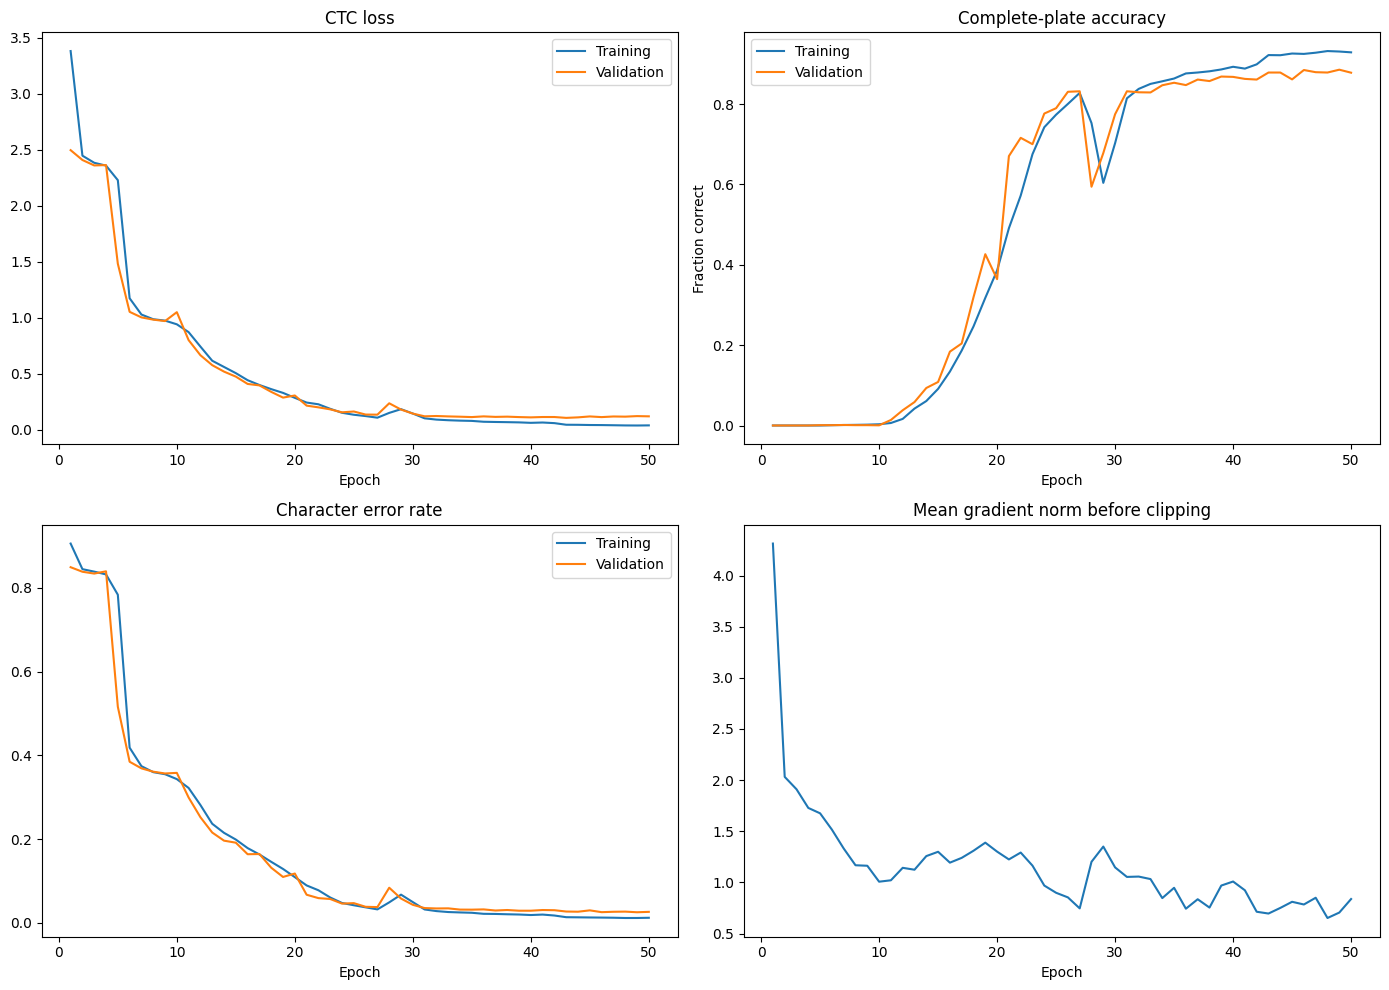

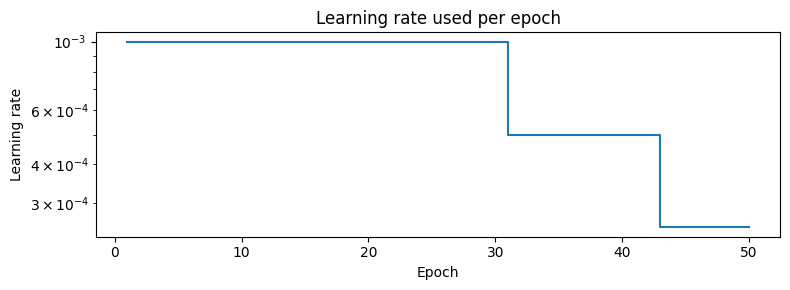

In [20]:
epoch_numbers = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.plot(epoch_numbers, history["train_loss"], label="Training")
plt.plot(epoch_numbers, history["val_loss"], label="Validation")
plt.title("CTC loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(epoch_numbers, history["train_accuracy"], label="Training")
plt.plot(epoch_numbers, history["val_accuracy"], label="Validation")
plt.title("Complete-plate accuracy")
plt.xlabel("Epoch")
plt.ylabel("Fraction correct")
plt.legend()

plt.subplot(2, 2, 3)
plt.plot(epoch_numbers, history["train_cer"], label="Training")
plt.plot(epoch_numbers, history["val_cer"], label="Validation")
plt.title("Character error rate")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(epoch_numbers, history["gradient_norm"])
plt.title("Mean gradient norm before clipping")
plt.xlabel("Epoch")

plt.tight_layout()
plt.savefig(os.path.join(save_folder, "training_curves.png"), dpi=150)
plt.show()

plt.figure(figsize=(8, 3))
plt.step(epoch_numbers, history["learning_rate"], where="post")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.title("Learning rate used per epoch")
plt.tight_layout()
plt.savefig(os.path.join(save_folder, "learning_rate.png"), dpi=150)
plt.show()


In [21]:
checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

assert checkpoint["character_to_index"] == character_to_index, "Checkpoint vocabulary differs. Retrain with merged labels."

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

character_to_index = checkpoint["character_to_index"]
index_to_character = checkpoint["index_to_character"]
blank_id = checkpoint["blank_id"]

print("Loaded best epoch:", checkpoint["epoch"])

images, targets, target_lengths = next(iter(val_loader))
true_labels = targets_to_text(targets, target_lengths)

with torch.no_grad():
    log_probs = model(images.to(device))

predicted_labels = decode_predictions(log_probs, index_to_character, blank_id)

for index in range(min(10, len(predicted_labels))):

    print("True:     ", list(true_labels[index]))
    print("Predicted:", list(predicted_labels[index]))
    print("Correct:  ", predicted_labels[index] == true_labels[index])
    print()


Loaded best epoch: 49
True:      ['2', '5', 'ت', '7', '1', '4', '3', '3']
Predicted: ['2', '5', 'ت', '7', '1', '4', '3', '3']
Correct:   True

True:      ['7', '4', 'ج', '8', '2', '4', '9', '9']
Predicted: ['7', '4', 'ج', '8', '2', '4', '9', '9']
Correct:   True

True:      ['5', '2', 'ژ', '5', '3', '8', '1', '1']
Predicted: ['5', '2', 'ع', '5', '3', '8', '1', '1']
Correct:   False

True:      ['4', '6', 'ن', '2', '5', '6', '5', '5']
Predicted: ['4', '6', 'ن', '3', '5', '6', '5', '5']
Correct:   False

True:      ['6', '2', 'و', '7', '3', '8', '7', '7']
Predicted: ['6', '2', 'و', '7', '3', '8', '7', '7']
Correct:   True

True:      ['8', '8', 'ع', '1', '8', '6', '7', '8']
Predicted: ['8', '8', 'ع', '1', '8', '6', '7', '8']
Correct:   True

True:      ['3', '3', 'ع', '7', '2', '2', '1', '3']
Predicted: ['3', '2', 'ع', '7', '2', '2', '1', '3']
Correct:   False

True:      ['7', '1', 'ع', '1', '7', '2', '7', '8']
Predicted: ['7', '1', 'ع', '1', '7', '2', '7', '8']
Correct:   True

True:  

## 11. Measure inference speed

This benchmark uses the loaded model in evaluation mode with float32 inputs. It measures batch size 1 and the available validation batch size, using 20 warm-up passes followed by 100 timed passes. CUDA synchronization ensures GPU work completes before timing stops.

Two measurements are recorded: the model forward pass alone, and the forward pass plus greedy decoding. The second includes moving predicted IDs to the CPU. Both exclude image loading, preprocessing, input transfer, and plate detection; these are recognition timings, not full vehicle-to-text pipeline timings.

The table reports mean, median, and 95th-percentile latency per batch, amortized milliseconds per image, and images per second. Batched throughput should not be interpreted as single-request latency. Hardware, input size, and precision are stored with `inference_speed.csv` so comparisons have context.

In [22]:
model.eval()
model.float()
benchmark_device = next(model.parameters()).device

benchmark_images, _, _ = next(iter(val_loader))
benchmark_images = benchmark_images.to(benchmark_device, dtype=torch.float32)

warmup_runs = 20
timed_runs = 100
batch_sizes = sorted(set([1, benchmark_images.size(0)]))
results = []

if benchmark_device.type == "cuda":
    hardware = torch.cuda.get_device_name(benchmark_device)
else:
    hardware = platform.processor() or platform.machine()

def synchronize_device():
    if benchmark_device.type == "cuda":
        torch.cuda.synchronize(benchmark_device)

with torch.inference_mode():
    for current_batch_size in batch_sizes:
        inputs = benchmark_images[:current_batch_size].contiguous()

        for include_decoding in [False, True]:
            for _ in range(warmup_runs):
                log_probs = model(inputs)
                if include_decoding:
                    decoded = decode_predictions(log_probs, index_to_character, blank_id)

            synchronize_device()
            durations = []

            for _ in range(timed_runs):
                synchronize_device()
                start_time = time.perf_counter()

                log_probs = model(inputs)
                if include_decoding:
                    decoded = decode_predictions(log_probs, index_to_character, blank_id)

                synchronize_device()
                durations.append(time.perf_counter() - start_time)

            mean_seconds = float(np.mean(durations))
            measurement = "Model + decoding" if include_decoding else "Model only"

            results.append({
                "measurement": measurement,
                "batch_size": current_batch_size,
                "mean_batch_ms": mean_seconds * 1000,
                "median_batch_ms": float(np.median(durations)) * 1000,
                "p95_batch_ms": float(np.percentile(durations, 95)) * 1000,
                "amortized_ms_per_image": mean_seconds * 1000 / current_batch_size,
                "images_per_second": current_batch_size / mean_seconds,
                "device": str(benchmark_device),
                "hardware": hardware,
                "torch_version": str(torch.__version__),
                "precision": "float32",
                "height": inputs.size(2),
                "width": inputs.size(3),
                "warmup_runs": warmup_runs,
                "timed_runs": timed_runs
            })

speed_results = pd.DataFrame(results)
print("Hardware:", hardware)
print("Device:", benchmark_device)
print("PyTorch:", torch.__version__)
display(speed_results.round(3))

speed_path = os.path.join(save_folder, "inference_speed.csv")
speed_results.to_csv(speed_path, index=False)
print("Saved:", speed_path)


Hardware: Tesla T4
Device: cuda:0
PyTorch: 2.11.0+cu128


,measurement,batch_size,mean_batch_ms,median_batch_ms,p95_batch_ms,amortized_ms_per_image,images_per_second,device,hardware,torch_version,precision,height,width,warmup_runs,timed_runs
0,Model only,1,4.304,4.044,5.951,4.304,232.335,cuda:0,Tesla T4,2.11.0+cu128,float32,64,256,20,100
1,Model + decoding,1,4.141,4.089,4.544,4.141,241.484,cuda:0,Tesla T4,2.11.0+cu128,float32,64,256,20,100
2,Model only,32,19.498,19.588,19.681,0.609,1641.216,cuda:0,Tesla T4,2.11.0+cu128,float32,64,256,20,100
3,Model + decoding,32,19.822,19.861,20.131,0.619,1614.387,cuda:0,Tesla T4,2.11.0+cu128,float32,64,256,20,100


Saved: /content/LPR_checkpoints_accuracy_v2/inference_speed.csv


## 12. Inspect mistaken predictions

The final cells load the chosen checkpoint and evaluate every validation image in a fixed order. Each incorrect prediction is recorded with its filename, ground-truth string, predicted string, edit distance, and predicted length. The full list is saved as `validation_mistakes.csv`.

The gallery displays a reproducible random sample of up to 12 mistakes at the model's resized input resolution. True characters are green and predicted characters are red. Drawing symbols separately preserves their stored order; empty predictions are shown explicitly. The gallery is also saved as `mistaken_samples.png`.

Use these examples to distinguish blur, clipped characters, ambiguous annotations, letter confusions, and sequence-length errors. Edit distance measures character mistakes, not prediction confidence. No labels are changed by this analysis.

`error_checkpoint_path` defaults to the best accuracy checkpoint. To inspect an existing compatible checkpoint without training again, set that path explicitly after preparing the data, model, and metric functions. The `.pt` file must be present in the runtime or mounted storage; a notebook does not embed those weights.

In [23]:
error_checkpoint_path = best_model_path
error_checkpoint = torch.load(error_checkpoint_path, map_location=device, weights_only=True)
assert error_checkpoint["character_to_index"] == val_dataset.character_to_index, "Dataset and checkpoint vocabularies differ."

model.load_state_dict(error_checkpoint["model_state_dict"])
model.eval()
index_to_character = error_checkpoint["index_to_character"]
blank_id = error_checkpoint["blank_id"]

error_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0)
error_rows = []
sample_index = 0
total_edits = 0
total_characters = 0

with torch.inference_mode():
    for images, targets, target_lengths in tqdm(error_loader, desc="Finding mistakes"):
        log_probs = model(images.to(device))
        predictions = decode_predictions(log_probs, index_to_character, blank_id)
        true_labels = targets_to_text(targets, target_lengths)

        for prediction, target in zip(predictions, true_labels):
            distance = edit_distance(prediction, target)
            total_edits += distance
            total_characters += len(target)
            if prediction != target:
                row = val_dataset.dataframe.iloc[sample_index]
                error_rows.append({
                    "dataset_index": sample_index,
                    "image_path": row["image_path"],
                    "true_label": target,
                    "predicted_label": prediction,
                    "edit_distance": distance,
                    "predicted_length": len(prediction)
                })
            sample_index += 1

mistakes_df = pd.DataFrame(error_rows, columns=[
    "dataset_index", "image_path", "true_label", "predicted_label", "edit_distance", "predicted_length"
])
error_folder = os.path.dirname(os.path.abspath(error_checkpoint_path))
mistakes_df.to_csv(os.path.join(error_folder, "validation_mistakes.csv"), index=False)

print("Checkpoint epoch:", error_checkpoint["epoch"])
print("Mistakes:", len(mistakes_df), "out of", sample_index)
print(f"Plate accuracy: {1 - len(mistakes_df) / sample_index:.2%}")
print(f"CER: {total_edits / total_characters:.2%}")
display(mistakes_df.head(20))


Finding mistakes:   0%|          | 0/75 [00:00<?, ?it/s]

Checkpoint epoch: 49
Mistakes: 275 out of 2400
Plate accuracy: 88.54%
CER: 2.51%


,dataset_index,image_path,true_label,predicted_label,edit_distance,predicted_length
0,2,20.jpg,52ژ53811,52ع53811,1,8
1,3,22.jpg,46ن25655,46ن35655,1,8
2,6,79.jpg,33ع72213,32ع72213,1,8
3,9,147.jpg,97ع46232,92ع46237,2,8
4,11,155.jpg,38ع48115,48ع48115,1,8
5,12,165.jpg,95ع79712,97ع79712,1,8
6,16,175.jpg,66ع11711,66ژ11711,1,8
7,23,227.jpg,29ت41211,61ب412181,4,9
8,27,287.jpg,51ت45422,51ت45432,1,8
9,37,367.jpg,28ت88616,28ت88611,1,8


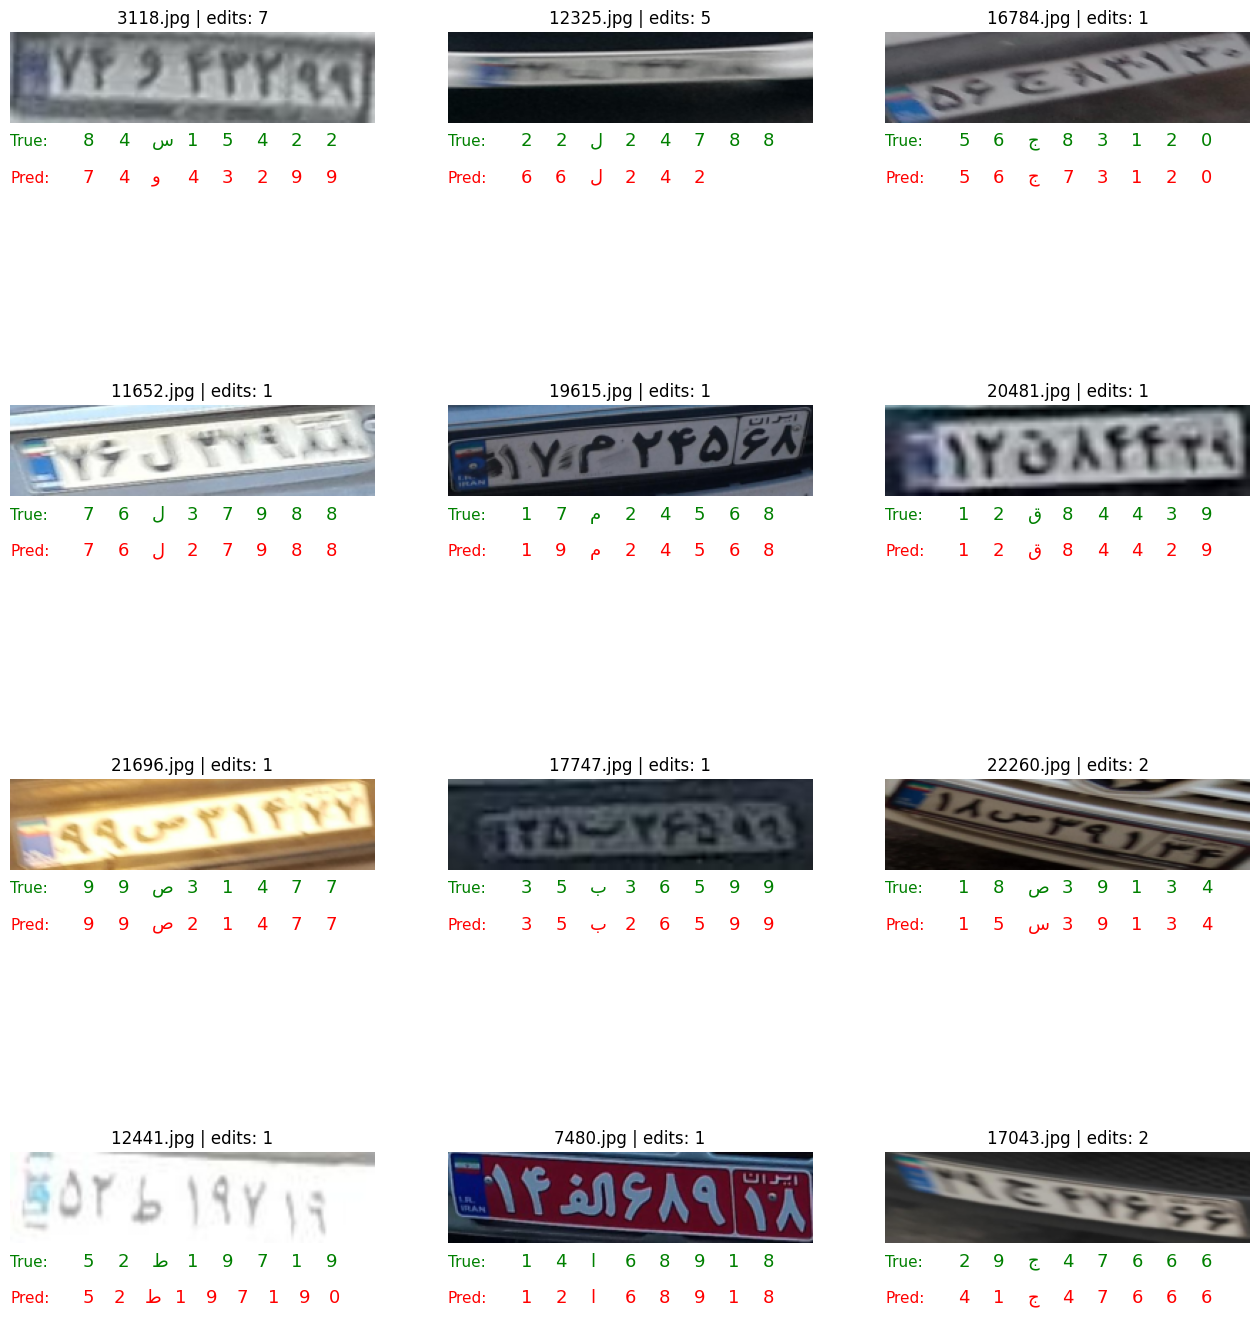

In [24]:
max_examples = 12

if mistakes_df.empty:
    print("No incorrect predictions in this validation set.")
else:
    examples = mistakes_df.sample(n=min(max_examples, len(mistakes_df)), random_state=42)
    columns = 3
    rows = math.ceil(len(examples) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(16, 4 * rows), squeeze=False)

    for axis in axes.flat:
        axis.axis("off")

    for axis, (_, row) in zip(axes.flat, examples.iterrows()):
        image, _, _ = val_dataset[int(row["dataset_index"])]
        preview = (image * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0)
        axis.imshow(preview)
        axis.set_title(f"{row['image_path']} | edits: {row['edit_distance']}")

        for text, y, color, title in [
            (row["true_label"], -0.25, "green", "True:"),
            (row["predicted_label"], -0.65, "red", "Pred:")
        ]:
            axis.text(0, y, title, transform=axis.transAxes, color=color, fontsize=11)
            if text == "":
                axis.text(0.20, y, "(empty)", transform=axis.transAxes, color=color)
            else:
                for position, character in enumerate(text):
                    x = 0.20 + 0.76 * position / max(len(text), 8)
                    axis.text(x, y, character, transform=axis.transAxes, color=color, fontsize=13)

    fig.subplots_adjust(hspace=1.6, wspace=0.2, bottom=0.15, top=0.94)
    plt.savefig(os.path.join(error_folder, "mistaken_samples.png"), dpi=150, bbox_inches="tight")
    plt.show()
